# Fenometria S2-EVI — áreas soja–milho–feijão (versão revisada)

**O que mudou em relação à versão anterior**

- **B0 (novo)**: instala `simplecube` e `wcpms_server` (do GitHub). Depois dele, reinicie a sessão.
- **B2**: não trava mais quando o Colab atualiza o NumPy; testa o Numba de verdade.
- **B7b (novo)**: lê o GeoPackage e gera o bbox a partir dos polígonos (ordem correta minx, miny, maxx, maxy).
- **B8**: período ajustado para **set/2024–ago/2025**, que é o calendário registrado no GeoPackage (antes: jan–jun/2026). Avisa se o cubo vier vazio.
- **B9 (novo)**: remove nodata (-9999), aplica a escala 0,0001 do EVI e preenche lacunas no tempo.
- **B11**: roda a fenometria **separadamente para cada safra** (soja, milho, feijão).
- **B12–B14 (novos)**: métricas por polígono (CSV), série de EVI com o calendário e mapas com os polígonos.
- **B16/B17**: GeoTIFFs separados por safra; o download sai num único .zip.

O GeoPackage é lido do Drive: `Meu Drive/SBSR/areas_soja_milho_feijao_epsg4326.gpkg`. Os GeoTIFFs são salvos em `Meu Drive/SBSR/phenometrics_tiff`.


In [ ]:
# ============================================================
# B0 — INSTALAR PACOTES (rodar 1x, num ambiente NOVO do Colab)
# ============================================================
# simplecube e wcpms_server fixam versões antigas (scipy, numpy...) que
# quebram o Colab. Por isso os dois entram com --no-deps e só instalamos
# o que realmente falta. A SciPy do Colab NÃO é tocada.

!pip install -q "xarray==2024.3.0" "rioxarray==0.17.0" pystac-client rasterio fiona pointpats
!pip install -q --no-deps simplecube git+https://github.com/GSansigolo/wcpm

# ------------------------------------------------------------
# O wcpms_server importa UMA função do pacote "datacube" (Open Data Cube),
# usada só para gravar o CRS no resultado. Instalar o datacube inteiro
# traria dezenas de dependências antigas; criamos um substituto mínimo.
# ------------------------------------------------------------
import os, site

_base = os.path.join(site.getsitepackages()[0], "datacube", "utils")
os.makedirs(_base, exist_ok=True)
open(os.path.join(os.path.dirname(_base), "__init__.py"), "w").close()
open(os.path.join(_base, "__init__.py"), "w").close()
with open(os.path.join(_base, "geometry.py"), "w") as f:
    f.write('''# Substituto mínimo de datacube.utils.geometry.assign_crs
import rioxarray

def assign_crs(xx, crs=None, crs_coord_name="spatial_ref"):
    if crs is None or str(crs) in ("None", ""):
        return xx
    try:
        return xx.rio.write_crs(str(crs), grid_mapping_name=crs_coord_name)
    except Exception:
        return xx
''')

# Teste num processo limpo
!python -c "import scipy, xarray, simplecube, wcpms_server; print('OK  SciPy', scipy.__version__, '| xarray', xarray.__version__)"

# Reinicia a sessão sozinho (o aviso "a sessão falhou" é esperado).
# Depois rode do B1 em diante, sem rodar o B0 de novo.
os.kill(os.getpid(), 9)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 34.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 84.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 2.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
OK  SciPy 1.16.3 | xarray 2024.3.0


In [1]:
# ============================================================
# B1 — TESTE DA GPU — GOOGLE COLAB
# ============================================================

import os
import shutil
import subprocess

print("=" * 70)
print("TESTANDO GPU NVIDIA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verificar se nvidia-smi existe
# ------------------------------------------------------------

nvidia_smi = shutil.which("nvidia-smi")

if nvidia_smi is None:
    print("nvidia-smi não foi encontrado.")
    print()
    print("A sessão atual provavelmente NÃO está conectada a uma GPU.")
    print()
    print("No Google Colab:")
    print("1. Ambiente de execução")
    print("2. Alterar tipo de ambiente de execução")
    print("3. Acelerador de hardware → T4 GPU")
    print("4. Salve/conecte novamente a sessão")
    print()
    print("Depois execute este bloco novamente.")

else:
    print("✓ nvidia-smi encontrado:")
    print(nvidia_smi)
    print()

    # --------------------------------------------------------
    # 2. Informações da GPU
    # --------------------------------------------------------

    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True
    )

    print(result.stdout)

    if result.returncode != 0:
        print("nvidia-smi apresentou um erro:")
        print(result.stderr)

    # --------------------------------------------------------
    # 3. Detectar nome da GPU
    # --------------------------------------------------------

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=name,memory.total,driver_version",
            "--format=csv,noheader"
        ],
        capture_output=True,
        text=True
    )

    gpu_info = result.stdout.strip()

    print("=" * 70)
    print("GPU DETECTADA")
    print("=" * 70)
    print(gpu_info)

    if "T4" in gpu_info:
        print("\n NVIDIA T4 DETECTADA COM SUCESSO!")
    else:
        print("\n Uma GPU NVIDIA foi detectada, mas não é uma T4.")

TESTANDO GPU NVIDIA
✓ nvidia-smi encontrado:
/opt/bin/nvidia-smi

Mon Sep 21 20:11:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |      

In [2]:
# ============================================================
# B2 — VERIFICAR AMBIENTE (NumPy / SciPy / Numba)
# ============================================================
# Antes esta célula levantava RuntimeError se o NumPy fosse > 2.0.
# O Colab atualiza o NumPy com frequência; agora ela só avisa.

import sys
import numpy as np
import scipy
import numba

print("=" * 70)
print("AMBIENTE PYTHON")
print("=" * 70)
print("Python:", sys.version)
print("NumPy :", np.__version__)
print("SciPy :", scipy.__version__)
print("Numba :", numba.__version__)

try:
    @numba.njit
    def _teste(a):
        return a.sum()
    _teste(np.arange(10, dtype=np.float32))
    print("\n✓ NumPy compatível com Numba")
except Exception as e:
    print("\n⚠ Numba não conseguiu compilar com este NumPy:", e)
    print("  Tente: !pip install -U numba  e reinicie a sessão.")


AMBIENTE PYTHON
Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
NumPy : 2.0.2
SciPy : 1.16.3
Numba : 0.60.0

✓ NumPy compatível com Numba


In [3]:
# ============================================================
# B3 — TESTE DO AMBIENTE CIENTÍFICO
# ============================================================

import numpy as np
import scipy
import xarray as xr
import matplotlib.pyplot as plt

print("=" * 70)
print("AMBIENTE CIENTÍFICO")
print("=" * 70)

print("NumPy :", np.__version__)
print("SciPy :", scipy.__version__)
print("Xarray:", xr.__version__)

# Teste NumPy
x = np.random.random((1000, 1000)).astype(np.float32)

# Teste Xarray
da = xr.DataArray(
    x,
    dims=("y", "x")
)

# Teste SciPy
from scipy.ndimage import gaussian_filter

y = gaussian_filter(x, sigma=1)

print("\n NumPy funcionando")
print(" Xarray funcionando")
print(" SciPy funcionando")

del x, y, da

print("=" * 70)


AMBIENTE CIENTÍFICO
NumPy : 2.0.2
SciPy : 1.16.3
Xarray: 2024.3.0

 NumPy funcionando
 Xarray funcionando
 SciPy funcionando


In [4]:
# ============================================================
# B4 — CUPY + NVIDIA T4
# ============================================================

import cupy as cp

print("=" * 70)
print("CUDA / T4")
print("=" * 70)

print("CuPy:", cp.__version__)
print("CUDA disponível:", cp.cuda.is_available())

if not cp.cuda.is_available():
    raise RuntimeError("CuPy não encontrou a T4.")

cp.cuda.Device(0).use()

gpu_name = cp.cuda.runtime.getDeviceProperties(0)["name"]

if isinstance(gpu_name, bytes):
    gpu_name = gpu_name.decode()

print("GPU:", gpu_name)

# Teste
a_gpu = cp.random.random(
    (5000, 5000),
    dtype=cp.float32
)

b_gpu = cp.sin(a_gpu) + a_gpu ** 2

cp.cuda.Stream.null.synchronize()

print(" Cálculo executado na T4")

del a_gpu, b_gpu

cp.get_default_memory_pool().free_all_blocks()

print("=" * 70)
print(" T4 FUNCIONANDO")
print("=" * 70)


CUDA / T4
CuPy: 14.0.1
CUDA disponível: True
GPU: Tesla T4
 Cálculo executado na T4
 T4 FUNCIONANDO


In [5]:
# ============================================================
# B5 — IMPORTAR WCPMS
# ============================================================

print("=" * 70)
print("IMPORTANDO WCPMS")
print("=" * 70)

from wcpms_server import (
    params_phenometrics,
    phenometrics_data_cube
)

print(" params_phenometrics importado")
print(" phenometrics_data_cube importado")

print("=" * 70)
print(" WCPMS FUNCIONANDO")
print("=" * 70)


IMPORTANDO WCPMS
 params_phenometrics importado
 phenometrics_data_cube importado
 WCPMS FUNCIONANDO


In [6]:
# ============================================================
# B6 — IMPORTAÇÕES COMPLETAS DO PROJETO
# ============================================================

import os
import gc
import time

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cupy as cp

from simplecube import simple_cube

from wcpms_server import (
    params_phenometrics,
    phenometrics_data_cube
)

cp.cuda.Device(0).use()

gpu_name = cp.cuda.runtime.getDeviceProperties(0)["name"]

if isinstance(gpu_name, bytes):
    gpu_name = gpu_name.decode()

print("=" * 70)
print("PROJETO WCPMS + SIMPLECUBE + T4")
print("=" * 70)

print("NumPy :", np.__version__)
print("Xarray:", xr.__version__)
print("CuPy  :", cp.__version__)
print("GPU   :", gpu_name)
print("CUDA  :", cp.cuda.is_available())

print("=" * 70)
print(" AMBIENTE PRONTO")
print("=" * 70)


PROJETO WCPMS + SIMPLECUBE + T4
NumPy : 2.0.2
Xarray: 2024.3.0
CuPy  : 14.0.1
GPU   : Tesla T4
CUDA  : True
 AMBIENTE PRONTO


In [7]:
# ============================================================
# B7 — CONFIGURAÇÃO DO STAC
# ============================================================

stac_url = "https://data.inpe.br/bdc/stac/v1"

print("=" * 70)
print("STAC")
print("=" * 70)

print("URL:", stac_url)

print(" STAC configurado")


STAC
URL: https://data.inpe.br/bdc/stac/v1
 STAC configurado


In [8]:
# ============================================================
# B7b — ÁREA DE ESTUDO A PARTIR DO GEOPACKAGE
# ============================================================
# Lê os polígonos direto do Google Drive (pasta SBSR).

import os
import geopandas as gpd
from google.colab import drive

# Conecta o Google Drive (pede permissão na primeira vez)
drive.mount("/content/drive")

# Arquivo em: Meu Drive → SBSR
GPKG_PATH = "/content/drive/MyDrive/SBSR/areas_soja_milho_feijao_epsg4326.gpkg"

if not os.path.exists(GPKG_PATH):
    raise FileNotFoundError(
        f"Não encontrei {GPKG_PATH}. Confira o nome da pasta/arquivo no Drive."
    )

areas = gpd.read_file(GPKG_PATH)
areas = areas.to_crs(4326)

print("=" * 70)
print("ÁREAS DE REFERÊNCIA")
print("=" * 70)
print(f"Polígonos: {len(areas)}")
print(areas.drop(columns="geometry").to_string(index=False))

areas_ha = areas.to_crs(5880).area / 1e4
print("\nÁrea por polígono (ha):", [round(a, 1) for a in areas_ha])
print(f"Área total: {areas_ha.sum():.1f} ha")

# bbox com margem de ~200 m, na ordem minx, miny, maxx, maxy
margem = 0.002
minx, miny, maxx, maxy = areas.total_bounds
bbox = f"{minx - margem:.6f}, {miny - margem:.6f}, {maxx + margem:.6f}, {maxy + margem:.6f}"
print("\nbbox:", bbox)


Mounted at /content/drive
ÁREAS DE REFERÊNCIA
Polígonos: 4
Sep_2024 Oct_2024 Nov_2024 Dec_2024 Jan_2025 Fev_2025 Mar_2025 Apr_2025 May_2025 Jun_2025 Jul_2025 Ago_2025  id
    Soja     Soja     Soja     Soja     Soja    Milho    Milho    Milho    Milho   Feijao   Feijao   Feijao   1
    Soja     Soja     Soja     Soja     Soja    Milho    Milho    Milho    Milho   Feijao   Feijao   Feijao   2
    Soja     Soja     Soja     Soja     Soja    Milho    Milho    Milho    Milho   Feijao   Feijao   Feijao   3
    Soja     Soja     Soja     Soja     Soja    Milho    Milho    Milho    Milho   Feijao   Feijao   Feijao   4

Área por polígono (ha): [112.4, 52.4, 85.1, 111.9]
Área total: 361.8 ha

bbox: -52.290413, -13.095870, -52.255074, -13.071876


In [9]:
# ============================================================
# B8 — DATA CUBE SENTINEL-2 EVI
# ============================================================
# O período agora cobre o calendário do GeoPackage
# (Soja set/2024–jan/2025, Milho fev–mai/2025, Feijão jun–ago/2025).
# O período antigo (jan–jun/2026) não coincidia com esse calendário.
# Atenção: ~23 composições de 16 dias; pode levar 20–30 min.

DATA_INICIO = "2024-09-01"
DATA_FIM    = "2025-08-31"

print("=" * 70)
print("CRIANDO DATA CUBE S2-EVI")
print("=" * 70)

inicio = time.perf_counter()

S2_EVI_cube = simple_cube(
    stac_url=stac_url,
    collection="S2-16D-2",
    start_date=DATA_INICIO,
    end_date=DATA_FIM,
    bbox=bbox,
    bands=["EVI"]
)

tempo = time.perf_counter() - inicio

# O simple_cube ignora silenciosamente as cenas que falham no download.
# Se todas falharem, o cubo volta vazio — melhor parar aqui com uma mensagem clara.
if S2_EVI_cube is None or "evi" not in S2_EVI_cube:
    raise RuntimeError(
        "O data cube voltou vazio. Causas comuns: o servidor do BDC não respondeu "
        "(tente de novo), bbox fora da cobertura, ou período sem cenas."
    )

print(f"\n✓ Data Cube criado — {S2_EVI_cube.sizes['time']} datas")
print(f"Tempo: {tempo:.2f} segundos")
print(S2_EVI_cube)


CRIANDO DATA CUBE S2-EVI


Fetching... : 100%|██████████| 24/24 [00:00<00:00, 52.75 scenes/s]



✓ Data Cube criado — 24 datas
Tempo: 1706.84 segundos
<xarray.Dataset> Size: 5MB
Dimensions:      (band: 1, x: 380, y: 273, time: 24)
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 3kB 5.183e+06 5.183e+06 ... 5.186e+06 5.186e+06
  * y            (y) float64 2kB 9.879e+06 9.879e+06 ... 9.876e+06 9.876e+06
    spatial_ref  int64 8B 0
  * time         (time) datetime64[ns] 192B 2024-08-28 2024-09-13 ... 2025-08-29
Data variables:
    evi          (time, band, y, x) int16 5MB 1780 1842 1839 ... 3837 3518 2880


In [10]:
# ============================================================
# B9 — PRÉ-PROCESSAMENTO DO EVI (nodata + escala)
# ============================================================
# O EVI do BDC é int16 com fator de escala 0,0001 e nodata = -9999.
# O simple_cube não aplica nem um nem outro. Sem isso, os -9999
# entram no cálculo como "vales" e o abs_value=0.1 do B10 fica
# numa escala diferente (0,1 contra valores até ~10000).

crs_cubo = S2_EVI_cube["evi"].rio.crs

evi = S2_EVI_cube["evi"]
evi = evi.where(evi != -9999)
evi = (evi * 0.0001).astype("float32")
evi = evi.where((evi >= -0.2) & (evi <= 1.0))  # descarta valores fisicamente impossíveis
frac_nan = float(evi.isnull().mean())

# Preenche lacunas (nuvem/nodata) no tempo — o phenolopy não lida bem com NaN
evi = evi.interpolate_na(dim="time", method="linear")
try:
    evi = evi.bfill("time").ffill("time")
except Exception:
    evi = evi.fillna(evi.mean("time"))

evi = evi.rio.write_crs(crs_cubo)
evi.name = "evi"

print("=" * 70)
print("EVI PRÉ-PROCESSADO")
print("=" * 70)
print("Shape  :", evi.shape, evi.dims)
print(f"Faixa  : {float(evi.min()):.3f} a {float(evi.max()):.3f}")
print(f"Pixels sem dado (antes do preenchimento): {frac_nan:.1%}")
print("Datas  :", [str(t)[:10] for t in evi.time.values])


EVI PRÉ-PROCESSADO
Shape  : (24, 1, 273, 380) ('time', 'band', 'y', 'x')
Faixa  : -0.172 a 1.000
Pixels sem dado (antes do preenchimento): 0.8%
Datas  : ['2024-08-28', '2024-09-13', '2024-09-29', '2024-10-15', '2024-10-31', '2024-11-16', '2024-12-02', '2024-12-18', '2025-01-01', '2025-01-17', '2025-02-02', '2025-02-18', '2025-03-06', '2025-03-22', '2025-04-07', '2025-04-23', '2025-05-09', '2025-05-25', '2025-06-10', '2025-06-26', '2025-07-12', '2025-07-28', '2025-08-13', '2025-08-29']


In [11]:
# ============================================================
# B10 — CONFIGURAÇÃO PHENOMETRICS
# ============================================================

config = params_phenometrics(
    peak_metric="pos",
    base_metric="vos",
    method="seasonal_amplitude",
    factor=0.2,
    thresh_sides="two_sided",
    abs_value=0.1
)

print("=" * 70)
print("CONFIGURAÇÃO FENOLÓGICA")
print("=" * 70)

print(config)

print("\n Configuração criada")


CONFIGURAÇÃO FENOLÓGICA
{'peak_metric': 'pos', 'base_metric': 'vos', 'method': 'seasonal_amplitude', 'factor': 0.2, 'thresh_sides': 'two_sided', 'abs_value': 0.1, 'date_format': None}

 Configuração criada


In [18]:
# ============================================================
# B11 — PHENOMETRICS POR SAFRA (Soja, Milho, Feijão)
# ============================================================
# O phenolopy extrai UMA estação por série. Como essas áreas têm
# três cultivos no ano, rodar a série inteira de uma vez mistura
# tudo (o pico da soja "vence"). Aqui cada cultura roda na sua janela.
#
# As janelas vão de VALE a VALE da curva de EVI (não do mês cheio do
# calendário), e se sobrepõem um pouco: assim a subida de cada cultura
# fica inteira dentro da janela, mesmo em talhões semeados mais cedo.
#
# O phenolopy devolve os *_times em DIA DO ANO. A janela da soja cruza
# a virada do ano (set→jan), o que quebrava o EOS e dava LOS negativo.
# Por isso cada janela é "deslocada" para começar em 1º de janeiro:
# o *_times passa a ser "dia desde o início da janela".

JANELAS = {
    "soja":   ("2024-09-01", "2025-01-20"),
    "milho":  ("2025-01-10", "2025-05-31"),
    "feijao": ("2025-05-01", "2025-08-31"),
}

import pandas as pd

resultados = {}

for cultura, (ini, fim) in JANELAS.items():
    serie = evi.sel(time=slice(ini, fim))
    n = serie.sizes["time"]

    # desloca as datas para a janela começar em 1º de janeiro (sem virada de ano)
    t_ini = pd.Timestamp(ini)
    desloc = t_ini - pd.Timestamp(f"{t_ini.year}-01-01")
    serie = serie.assign_coords(time=pd.DatetimeIndex(serie.time.values) - desloc)
    print("=" * 70)
    print(f"{cultura.upper()} — {ini} a {fim} — {n} datas")
    print("=" * 70)

    if n < 5:
        print("⚠ Menos de 5 datas na janela — pulando.")
        continue

    t0 = time.perf_counter()
    try:
        ds = phenometrics_data_cube(da=serie, engine="phenolopy", config=config)
    except Exception as e:
        print(f"✗ Erro no phenometrics: {type(e).__name__}: {e}")
        continue

    resultados[cultura] = ds
    print(f"✓ Calculado em {time.perf_counter() - t0:.1f} s — {len(ds.data_vars)} métricas")

# Mantém a variável com o nome usado nas células seguintes
ds_phenos = resultados.get("soja")


SOJA — 2024-09-01 a 2025-01-20 — 9 datas
✓ Calculado em 0.3 s — 18 métricas
MILHO — 2025-01-10 a 2025-05-31 — 9 datas
✓ Calculado em 0.4 s — 18 métricas
FEIJAO — 2025-05-01 a 2025-08-31 — 8 datas
✓ Calculado em 0.3 s — 18 métricas


In [19]:
# ============================================================
# B12 — MÉTRICAS POR POLÍGONO (resposta sobre as áreas)
# ============================================================
# Recorta cada métrica pelos polígonos do GeoPackage e calcula a
# mediana. Os *_times são "dia desde o início da janela" (ver B11) e
# são convertidos em data. Pixels com *_times = 0 (métrica não detectada)
# ficam fora da mediana; a coluna n_falha_* conta quantos foram.

import pandas as pd

areas_proj = areas.to_crs(crs_cubo)

def preparar(da):
    if "band" in da.dims and da.sizes["band"] == 1:
        da = da.squeeze("band", drop=True)
    da = da.squeeze(drop=True)
    da.attrs.pop("grid_mapping", None)
    da.encoding.pop("grid_mapping", None)
    da = da.drop_vars([c for c in ["time"] if c in da.coords])
    da = da.rio.set_spatial_dims(x_dim="x", y_dim="y")
    return da.rio.write_crs(crs_cubo)

def dia_para_data(dia, cultura):
    """*_times = dia desde o início da janela (1 = primeiro dia)."""
    if not np.isfinite(dia) or dia <= 0:
        return pd.NaT
    return (pd.Timestamp(JANELAS[cultura][0]) + pd.Timedelta(days=float(dia) - 1)).normalize()

METRICAS = ["sos_times", "pos_times", "eos_times", "los_values",
            "sos_values", "pos_values", "eos_values", "aos_values", "vos_values"]

linhas = []
for cultura, ds in resultados.items():
    for i, pol in areas_proj.iterrows():
        linha = {"id": pol["id"], "cultura": cultura}
        for var in METRICAS:
            if var not in ds:
                continue
            try:
                rec = preparar(ds[var]).rio.clip([pol.geometry], areas_proj.crs, drop=True)
                v = rec.values.ravel()
                v = v[np.isfinite(v)]
                if var.endswith("_times"):
                    linha[f"n_falha_{var[:3]}"] = int((v <= 0).sum())
                    v = v[v > 0]
                val = float(np.median(v)) if v.size else np.nan
            except Exception:
                val = np.nan
            linha[var] = round(val, 3)
            if var.endswith("_times"):
                linha[var.replace("_times", "_data")] = dia_para_data(val, cultura)
        linhas.append(linha)

tabela = pd.DataFrame(linhas)
pd.set_option("display.width", 200)
print(tabela.to_string(index=False))

tabela.to_csv("phenometrics_por_poligono.csv", index=False)
print("\n✓ Salvo: phenometrics_por_poligono.csv")

 id cultura  n_falha_sos  sos_times   sos_data  n_falha_pos  pos_times   pos_data  n_falha_eos  eos_times   eos_data  los_values  sos_values  pos_values  eos_values  aos_values  vos_values
  1    soja            0       29.0 2024-09-29            0       77.0 2024-11-16            0      139.0 2025-01-17       110.0       0.246       0.895       0.208       0.711       0.185
  2    soja            0       61.0 2024-10-31            0       77.0 2024-11-16            0      139.0 2025-01-17        78.0       0.323       0.945       0.309       0.803       0.144
  3    soja            0       61.0 2024-10-31            0       93.0 2024-12-02            0      139.0 2025-01-17        78.0       0.313       0.894       0.248       0.736       0.158
  4    soja            0       29.0 2024-09-29            0       93.0 2024-12-02            0      139.0 2025-01-17       110.0       0.251       0.820       0.190       0.650       0.183
  1   milho            0        8.0 2025-01-17         

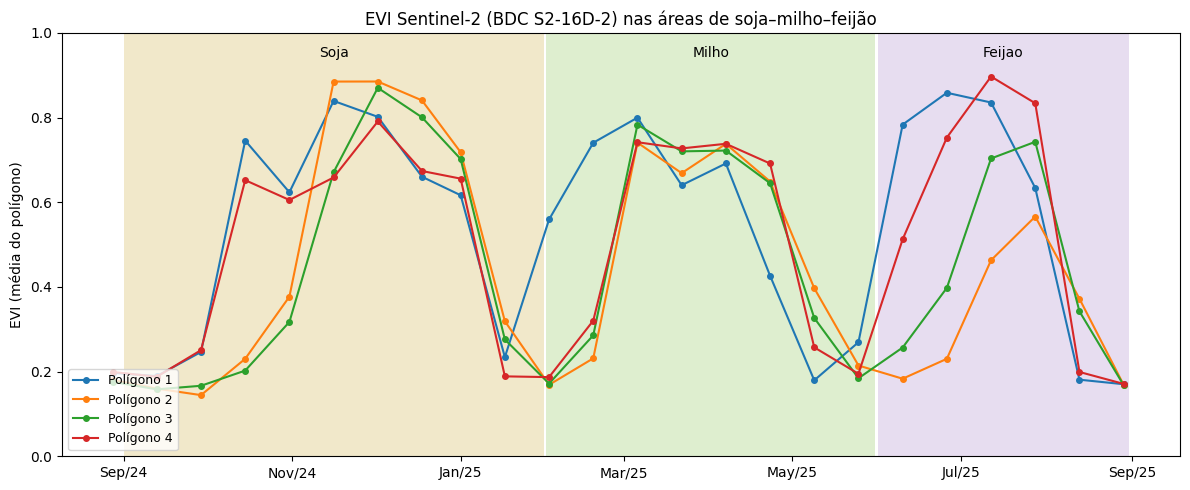

✓ Salvo: evi_series_poligonos.csv e evi_series_poligonos.png


In [20]:
# ============================================================
# B13 — SÉRIE TEMPORAL DE EVI POR POLÍGONO + CALENDÁRIO
# ============================================================

import matplotlib.dates as mdates

cores = {"soja": "#e8d9a8", "milho": "#c9e3b0", "feijao": "#d8c7e6"}

fig, ax = plt.subplots(figsize=(12, 5))

# faixas = calendário do GeoPackage
CALENDARIO = {
    "soja":   ("2024-09-01", "2025-01-31"),
    "milho":  ("2025-02-01", "2025-05-31"),
    "feijao": ("2025-06-01", "2025-08-31"),
}

for cultura, (ini, fim) in CALENDARIO.items():
    ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fim), color=cores[cultura], alpha=0.6, lw=0)
    meio = pd.Timestamp(ini) + (pd.Timestamp(fim) - pd.Timestamp(ini)) / 2
    ax.text(meio, 0.97, cultura.capitalize(), ha="center", va="top",
            transform=ax.get_xaxis_transform(), fontsize=10)

evi_xy = evi.squeeze("band", drop=True) if "band" in evi.dims else evi
evi_xy = evi_xy.rio.set_spatial_dims(x_dim="x", y_dim="y").rio.write_crs(crs_cubo)

series = {}
for _, pol in areas_proj.iterrows():
    rec = evi_xy.rio.clip([pol.geometry], areas_proj.crs, drop=True)
    s = rec.mean(dim=["x", "y"], skipna=True).to_series()
    series[f"id {pol['id']}"] = s
    ax.plot(s.index, s.values, marker="o", ms=4, label=f"Polígono {pol['id']}")

ax.set_ylabel("EVI (média do polígono)")
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b/%y"))
ax.legend(loc="lower left", fontsize=9)
ax.set_title("EVI Sentinel-2 (BDC S2-16D-2) nas áreas de soja–milho–feijão")
plt.tight_layout()
plt.savefig("evi_series_poligonos.png", dpi=200)
plt.show()

pd.DataFrame(series).to_csv("evi_series_poligonos.csv")
print("✓ Salvo: evi_series_poligonos.csv e evi_series_poligonos.png")

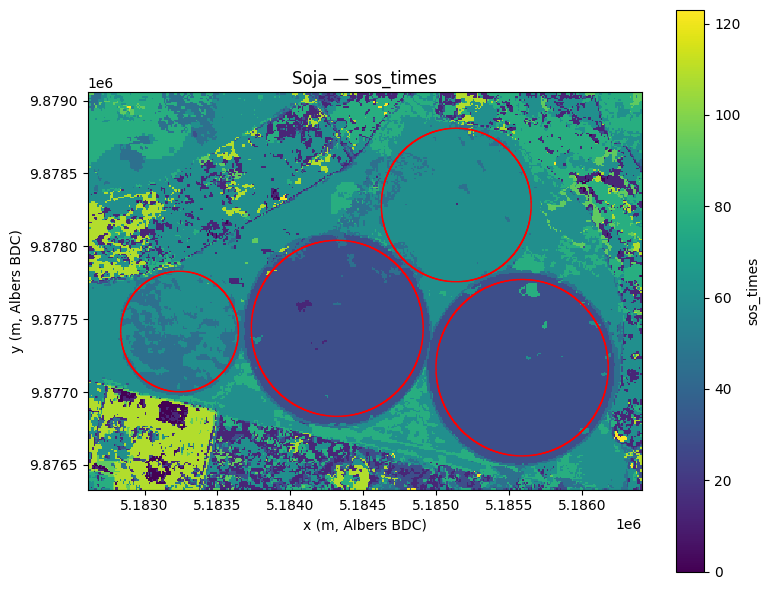

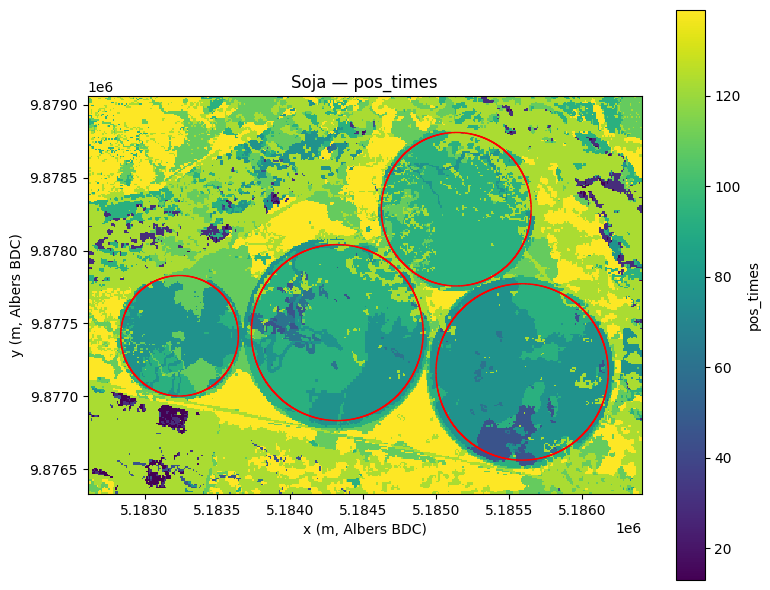

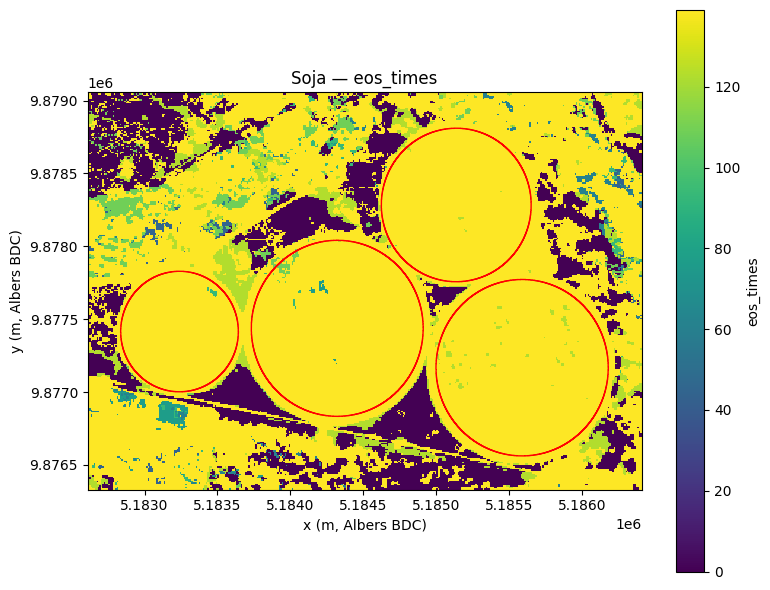

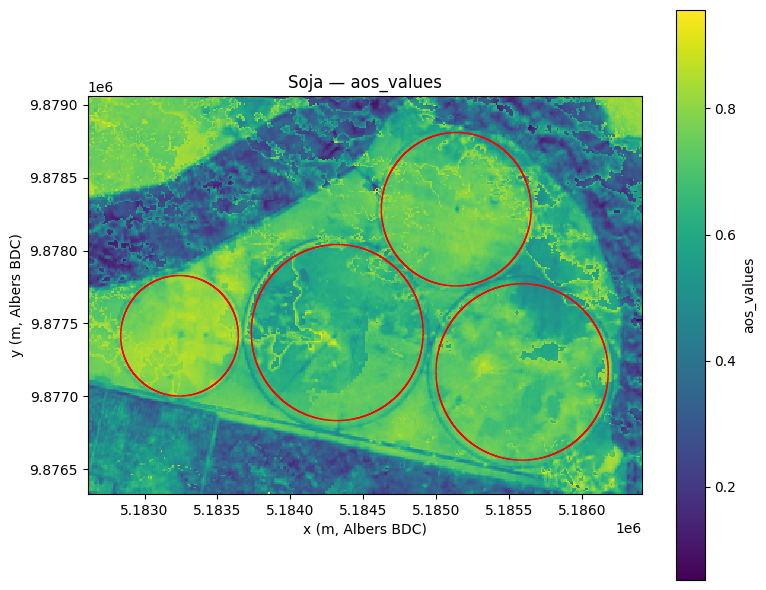

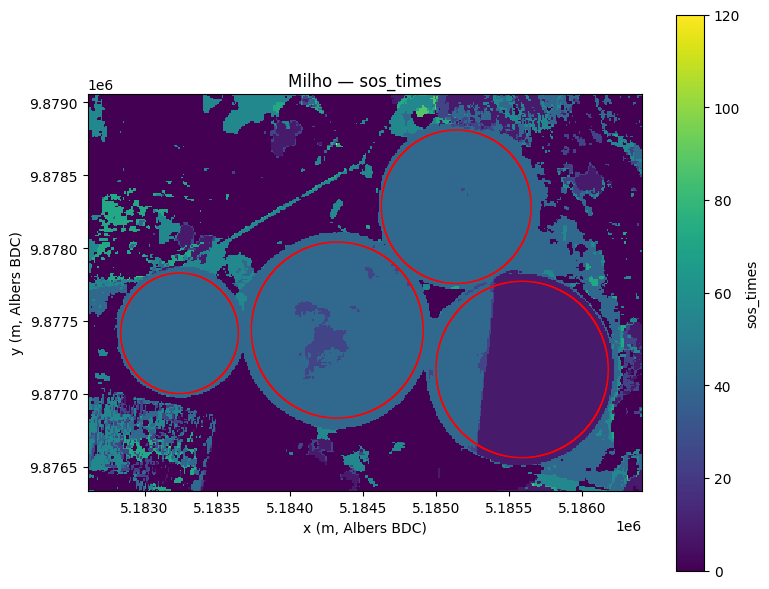

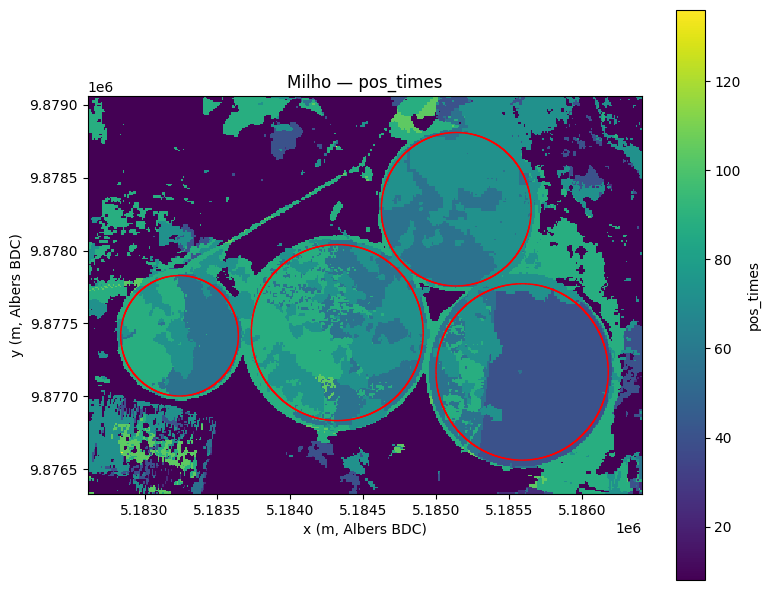

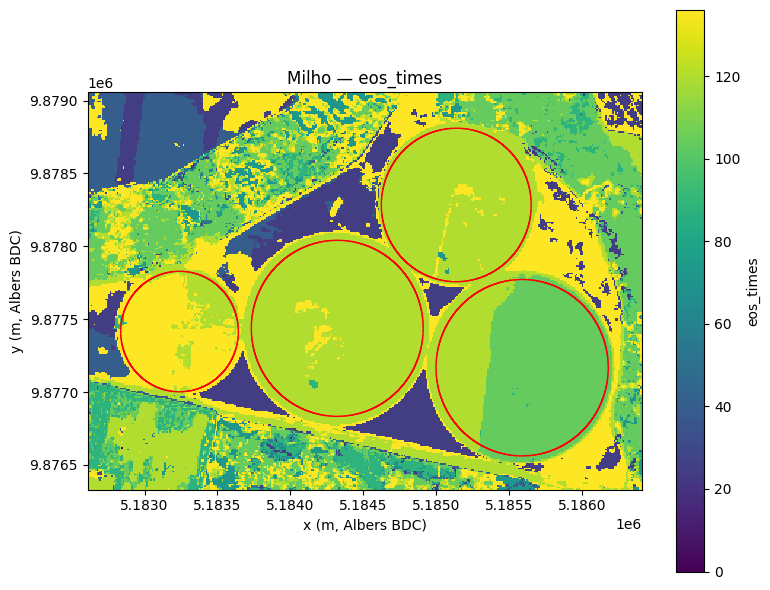

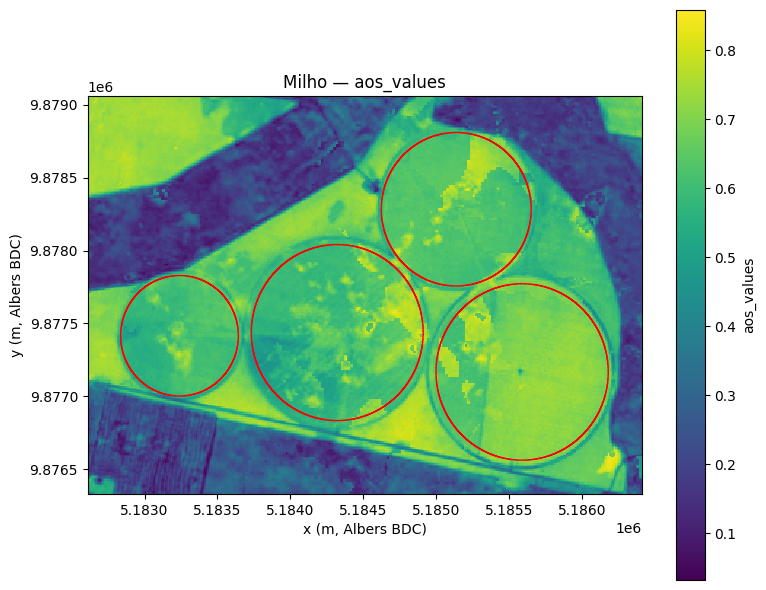

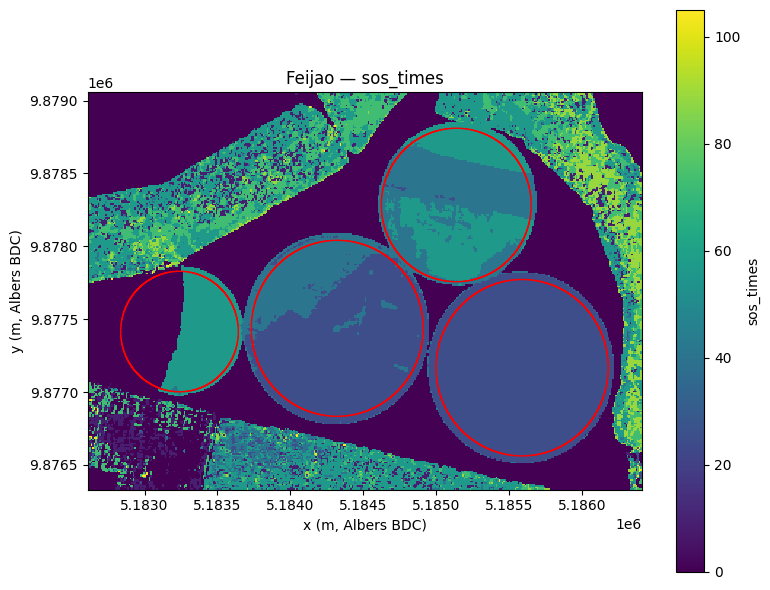

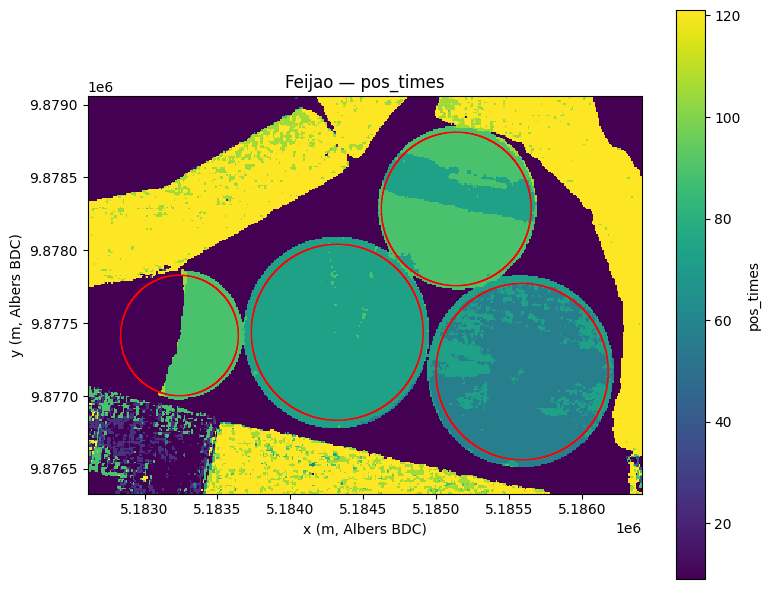

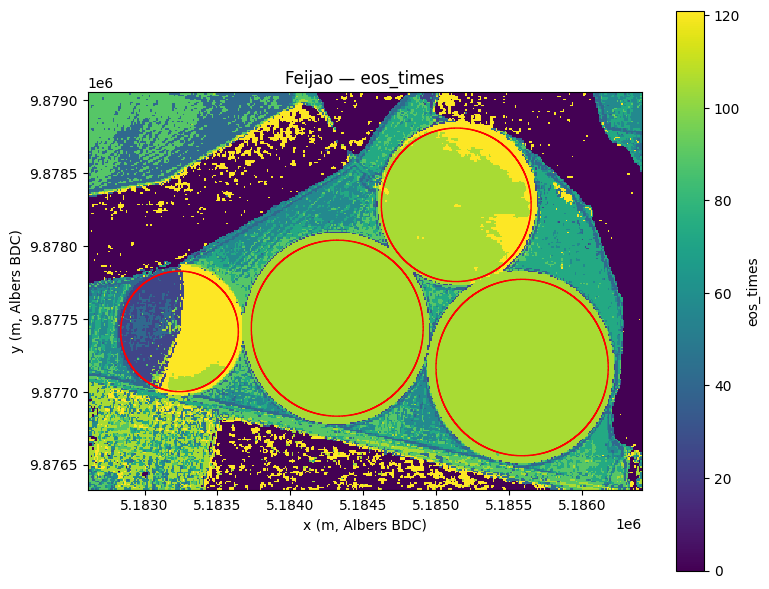

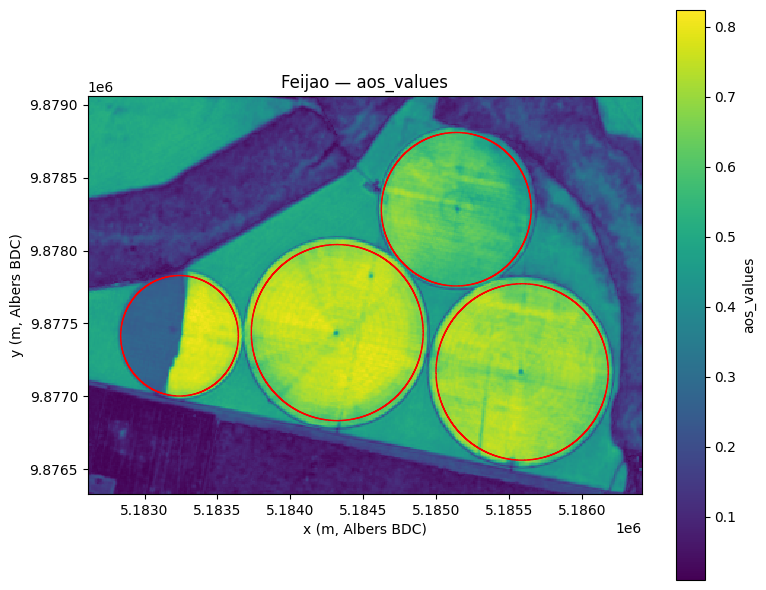

In [21]:
# ============================================================
# B14 — MAPAS DAS MÉTRICAS (por safra) COM OS POLÍGONOS
# ============================================================
# Obs.: os eixos estão em metros (projeção Albers do BDC), não em lat/lon.

for cultura, ds in resultados.items():
    for var in ["sos_times", "pos_times", "eos_times", "aos_values"]:
        if var not in ds:
            continue
        da_plot = preparar(ds[var])
        if bool(da_plot.isnull().all()):
            continue
        fig, ax = plt.subplots(figsize=(8, 6))
        da_plot.plot(ax=ax, cmap="viridis")
        areas_proj.boundary.plot(ax=ax, color="red", linewidth=1)
        ax.set_title(f"{cultura.capitalize()} — {var}")
        ax.set_xlabel("x (m, Albers BDC)")
        ax.set_ylabel("y (m, Albers BDC)")
        plt.tight_layout()
        plt.show()


In [22]:
# ============================================================
# B16 — SALVAR MÉTRICAS COMO GEOTIFF (uma pasta por safra)
# ============================================================

import os

# Salva direto no Drive (fica guardado depois que a sessão fecha)
output_dir = "/content/drive/MyDrive/SBSR/phenometrics_tiff"
os.makedirs(output_dir, exist_ok=True)

for cultura, ds in resultados.items():
    pasta = os.path.join(output_dir, cultura)
    os.makedirs(pasta, exist_ok=True)
    for var in ds.data_vars:
        da = preparar(ds[var])
        if not ("x" in da.dims and "y" in da.dims):
            continue
        arq = os.path.join(pasta, f"{var}.tif")
        da.rio.to_raster(arq, driver="GTiff")
    print(f"✓ {cultura}: {len(ds.data_vars)} GeoTIFFs em {pasta}")


✓ soja: 18 GeoTIFFs em /content/drive/MyDrive/SBSR/phenometrics_tiff/soja
✓ milho: 18 GeoTIFFs em /content/drive/MyDrive/SBSR/phenometrics_tiff/milho
✓ feijao: 18 GeoTIFFs em /content/drive/MyDrive/SBSR/phenometrics_tiff/feijao


In [23]:
# ============================================================
# B17 — BAIXAR TUDO EM UM ÚNICO ZIP
# ============================================================
# Baixar 18+ arquivos um a um costuma ser bloqueado pelo navegador
# ("vários downloads"). Um zip evita isso.

import shutil
from google.colab import files

for extra in ["phenometrics_por_poligono.csv", "evi_series_poligonos.csv", "evi_series_poligonos.png"]:
    if os.path.exists(extra):
        shutil.copy(extra, output_dir)

zip_path = shutil.make_archive("resultados_phenometrics", "zip", output_dir)
print("✓ Compactado:", zip_path)
files.download(zip_path)


✓ Compactado: /content/resultados_phenometrics.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>